# XGBoost Model

This notebook is split from `majorproject(1).ipynb`. Run cells from top to bottom.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os 

In [2]:
folder_path = r"C:\Users\Asus\Downloads\OneDrive_1_8-22-2026"
csv_files = glob.glob(os.path.join(folder_path,"*.csv"))
dataframes =[]
for file in csv_files:
    temp_df = pd.read_csv(file)
    dataframes.append(temp_df)

In [3]:
df =  pd.concat(dataframes,ignore_index=True)
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
print(df.iloc[:, -1].value_counts())

label
1    164673
0     93000
Name: count, dtype: int64


In [4]:
y = df["label"]
X = df.drop(columns=["label", "attack_cat", "id"])
X = pd.get_dummies(X, drop_first=True)
X = X.astype(np.float64)
X = X.to_numpy()
y = y.to_numpy()
X[X == np.inf] = np.nan
X[X == -np.inf] = np.nan

In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state = 42)


In [6]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values= np.nan,strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [7]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [8]:
print(np.isnan(X_train).sum())
print(np.isnan(X_test).sum())

0
0


In [9]:
print(np.isinf(X_train).sum())
print(np.isinf(X_test).sum())

0
0


In [10]:
pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

In [12]:
print(le.classes_)

[0 1]


In [13]:
xgb = XGBClassifier(n_estimators = 100, max_depth = 6, learning_rate = 0.1,random_state=42,n_jobs=1)
xgb.fit(X_train,y_train_encoded)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [14]:
y_pred_xgb = xgb.predict(X_test)

In [15]:
from sklearn.metrics import accuracy_score,classification_report
print("SVM accuracy: ",accuracy_score(y_test,y_pred_xgb))

SVM accuracy:  0.9415154749199574


In [16]:
print(classification_report(y_test,y_pred_xgb))

              precision    recall  f1-score   support

           0       0.91      0.93      0.92     18675
           1       0.96      0.95      0.95     32860

    accuracy                           0.94     51535
   macro avg       0.93      0.94      0.94     51535
weighted avg       0.94      0.94      0.94     51535



In [17]:
print(len(y_pred_xgb))
print(len(y_test_encoded))

51535
51535


In [18]:
from sklearn.metrics import confusion_matrix

cm_xgb = confusion_matrix(y_test_encoded, y_pred_xgb)

print("XGBoost Confusion Matrix:")
print(cm_xgb)

XGBoost Confusion Matrix:
[[17441  1234]
 [ 1780 31080]]


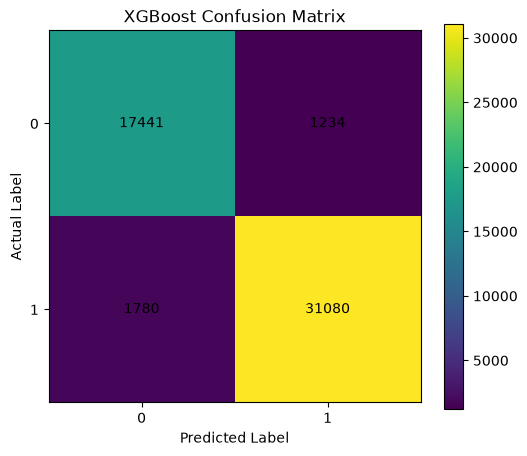

In [19]:
plt.figure(figsize=(6,5))
plt.imshow(cm_xgb)
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.colorbar()
plt.xticks([0, 1], le.classes_)
plt.yticks([0, 1], le.classes_)
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_xgb[i, j],
                 ha="center",
                 va="center")
plt.show()

In [20]:
feature_importance = xgb.feature_importances_

feature_names = pd.get_dummies(
    df.iloc[:, :-1],
    drop_first=True
).columns

importance_df = pd.DataFrame({
    "Feature": feature_names[:len(feature_importance)],
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(20))

              Feature  Importance
6                rate    0.480697
21             tcprtt    0.074124
37         ct_src_ltm    0.049961
20               dwin    0.039956
31   ct_src_dport_ltm    0.038663
16               djit    0.028545
172      service_dhcp    0.027878
157         proto_ttp    0.024096
23             ackdat    0.022630
32   ct_dst_sport_ltm    0.021264
4              sbytes    0.020014
158         proto_udp    0.019677
175  service_ftp-data    0.013778
3               dpkts    0.012480
10              dload    0.012302
28         ct_srv_src    0.011205
1                 dur    0.010067
24              smean    0.009382
25              dmean    0.008925
26        trans_depth    0.008539
